In [1]:
!pip uninstall -y -q segment-anything-hq segment-anything

In [2]:
!pip install -q "git+https://github.com/SysCV/sam-hq.git" ultralytics

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.4/46.4 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 21.8 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.8/75.8 kB 3.4 MB/s eta 0:00:00


In [3]:
import os
print(os.listdir("/kaggle/input/datasets/hemantdarur/yolomodel-inference/yolo_checkpoints/tooth_yolo/weights"))
print(os.listdir("/kaggle/input/datasets/alielhenidy/tooth-dataset/Tooth dataset v4/val/images")[:5])

['last.pt', 'best.pt']
['patient17-2.jpg', 'yahya6.jpg', 'IMG_2480.jpg', 'istockphoto-1005521304-612x612.jpg', 'IMG-20240819-WA0570.jpg']


In [4]:
from segment_anything import sam_model_registry
print(list(sam_model_registry.keys()))

['default', 'vit_h', 'vit_l', 'vit_b', 'vit_tiny']


/usr/local/lib/python3.12/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.12/dist-packages/timm/models/registry.py:4: FutureWarning: Importing from timm.models.registry is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.models", FutureWarning)
/usr/local/lib/python3.12/dist-packages/segment_anything/modeling/tiny_vit_sam.py:662: UserWarning: Overwriting tiny_vit_5m_224 in registry with segment_anything.modeling.tiny_vit_sam.tiny_vit_5m_224. This is because the name being registered conflicts with an existing name. Please check if this is not expected.
  return register_model(fn_wrapper)
/usr/local/lib/python3.12/dist-packages/segment_anything/modeling/tiny_vit_sam.py:662: UserWarning: Overwr

In [6]:
import segment_anything
print(segment_anything.__file__)
!pip show segment-anything-hq
!pip show segment-anything


/usr/local/lib/python3.12/dist-packages/segment_anything/__init__.py
Name: segment_anything
Version: 1.0
Summary: 
Home-page: 
Author: 
Author-email: 
License: 
Location: /usr/local/lib/python3.12/dist-packages
Requires: 
Required-by: 


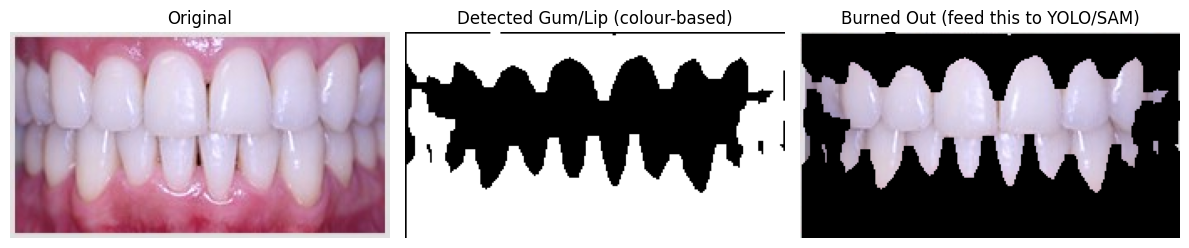

patient9-2.jpg: burned 62.4% of pixels as gum/lip -> /kaggle/working/outputs_gum_lip_suppression/patient9-2_gum_lip_suppression.png


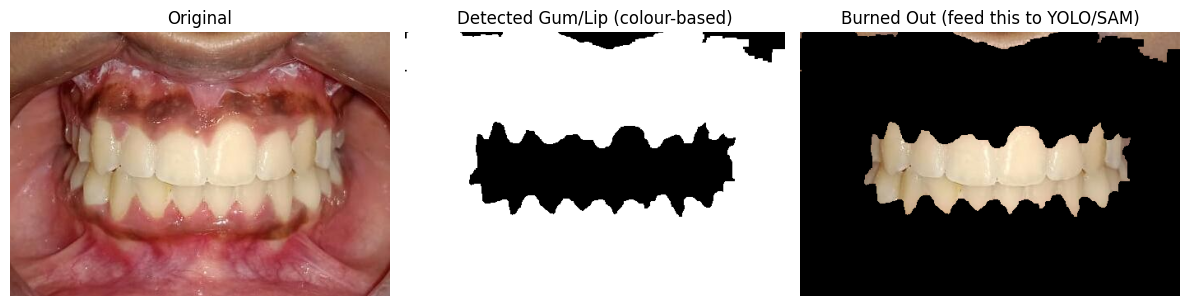

7836.jpg: burned 80.8% of pixels as gum/lip -> /kaggle/working/outputs_gum_lip_suppression/7836_gum_lip_suppression.png


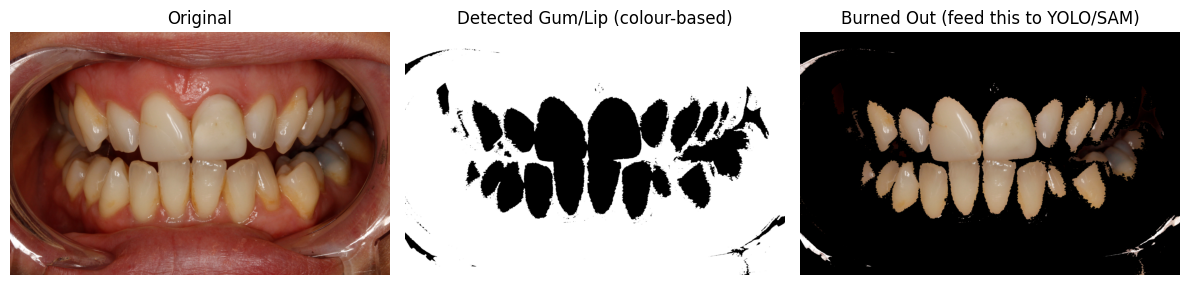

7018.jpg: burned 76.7% of pixels as gum/lip -> /kaggle/working/outputs_gum_lip_suppression/7018_gum_lip_suppression.png


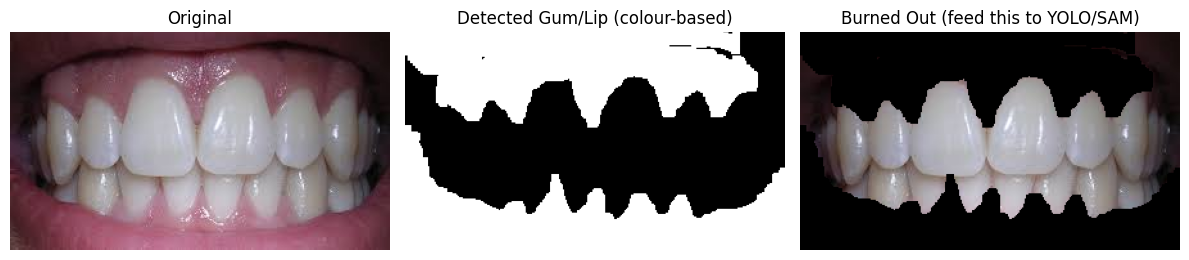

yahya1.jpg: burned 52.4% of pixels as gum/lip -> /kaggle/working/outputs_gum_lip_suppression/yahya1_gum_lip_suppression.png


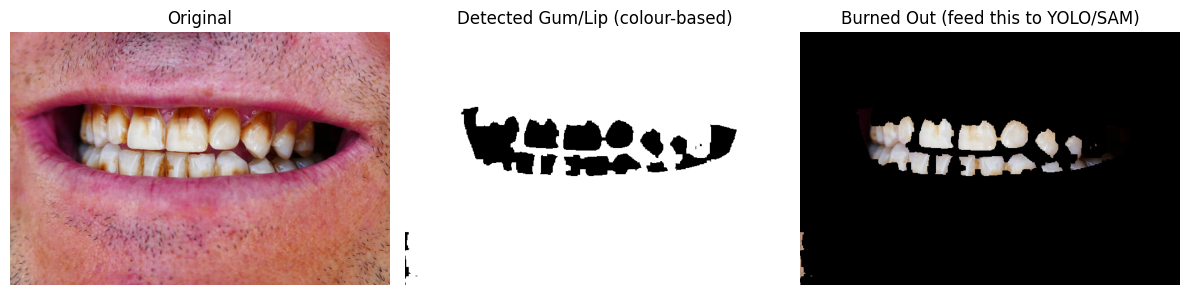

istockphoto-1002774754-612x612.jpg: burned 91.6% of pixels as gum/lip -> /kaggle/working/outputs_gum_lip_suppression/istockphoto-1002774754-612x612_gum_lip_suppression.png


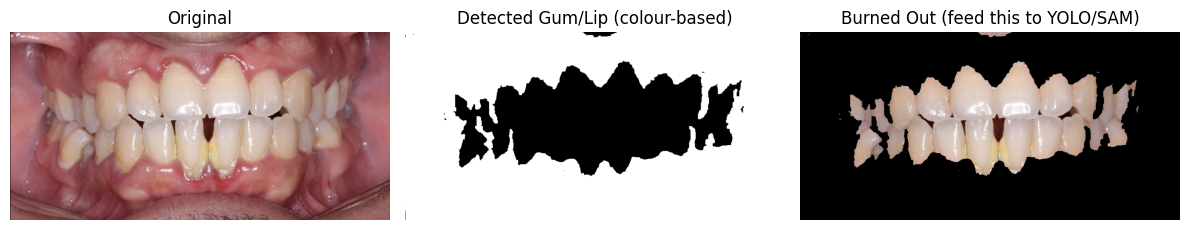

IMG_2423.jpg: burned 72.5% of pixels as gum/lip -> /kaggle/working/outputs_gum_lip_suppression/IMG_2423_gum_lip_suppression.png


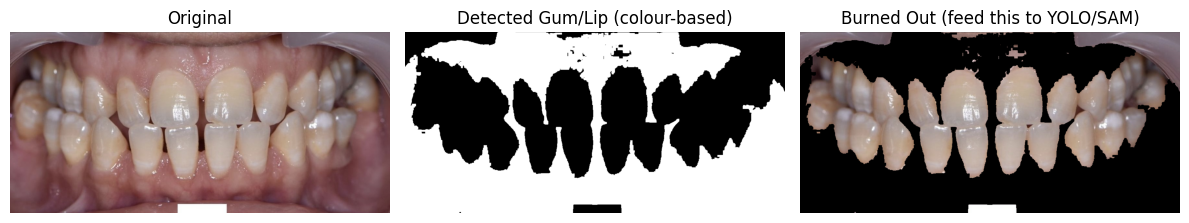

IMG_2385.jpg: burned 54.8% of pixels as gum/lip -> /kaggle/working/outputs_gum_lip_suppression/IMG_2385_gum_lip_suppression.png


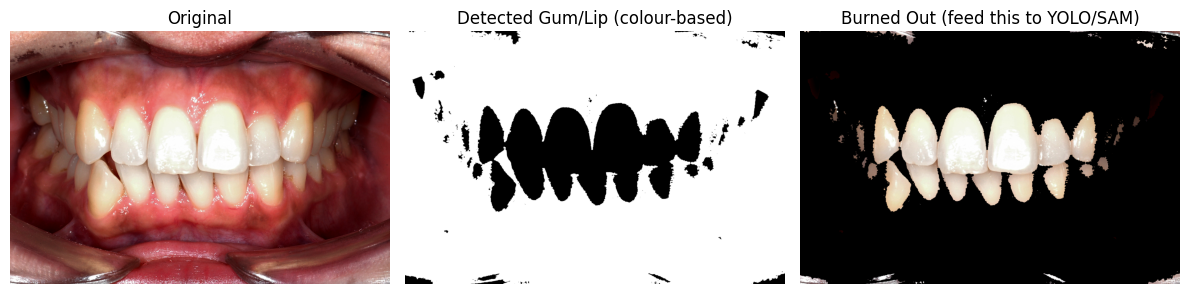

8764.jpg: burned 82.3% of pixels as gum/lip -> /kaggle/working/outputs_gum_lip_suppression/8764_gum_lip_suppression.png


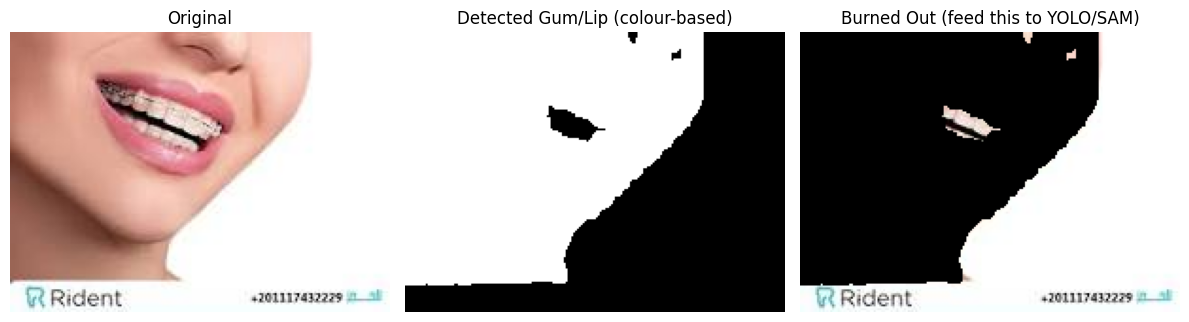

y9.jpeg: burned 56.0% of pixels as gum/lip -> /kaggle/working/outputs_gum_lip_suppression/y9_gum_lip_suppression.png


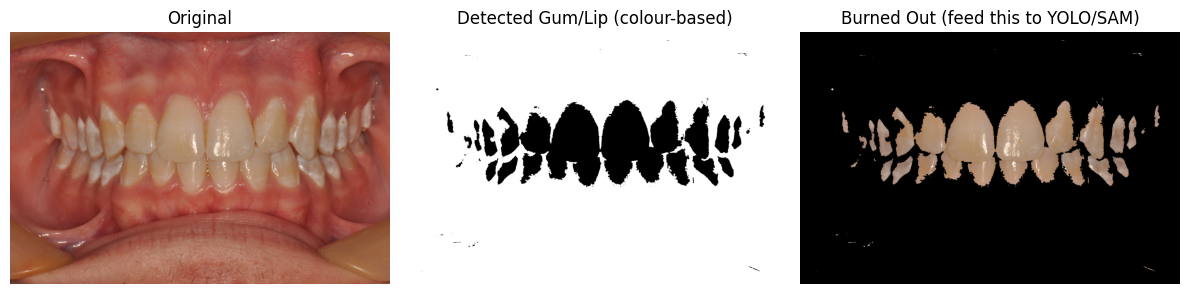

7758.jpg: burned 86.1% of pixels as gum/lip -> /kaggle/working/outputs_gum_lip_suppression/7758_gum_lip_suppression.png


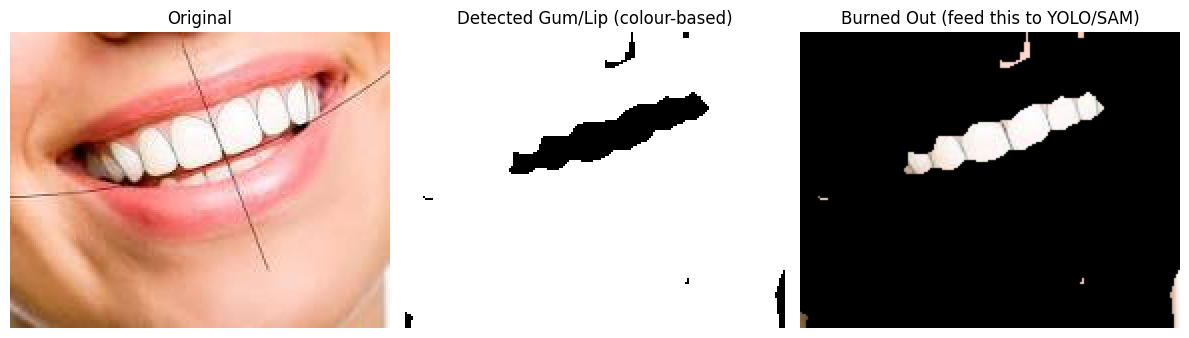

y17.jpeg: burned 94.0% of pixels as gum/lip -> /kaggle/working/outputs_gum_lip_suppression/y17_gum_lip_suppression.png


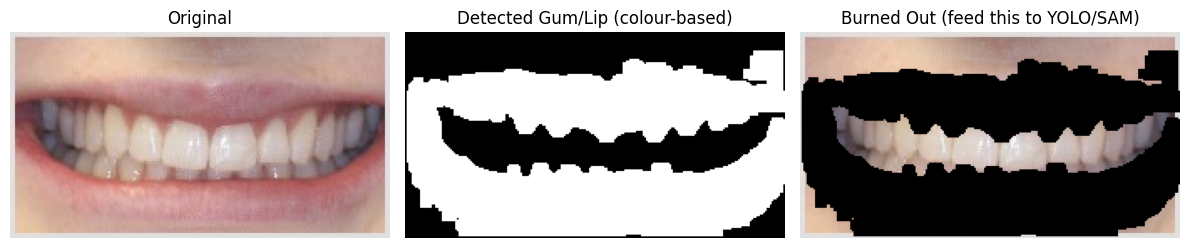

patient17-2.jpg: burned 60.8% of pixels as gum/lip -> /kaggle/working/outputs_gum_lip_suppression/patient17-2_gum_lip_suppression.png


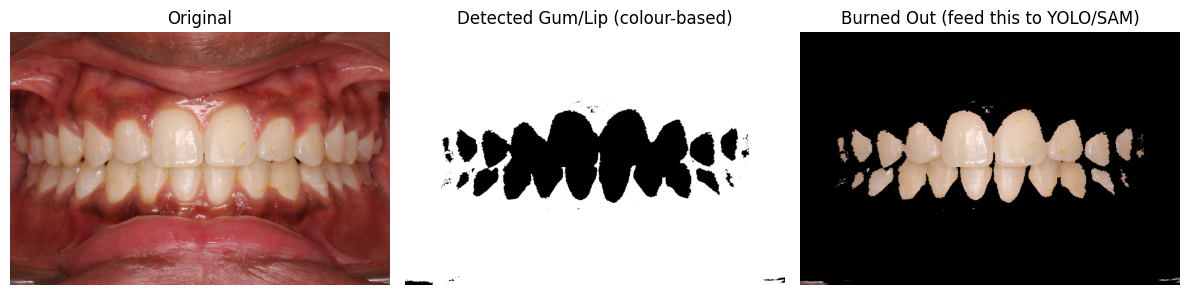

7625.jpg: burned 83.8% of pixels as gum/lip -> /kaggle/working/outputs_gum_lip_suppression/7625_gum_lip_suppression.png


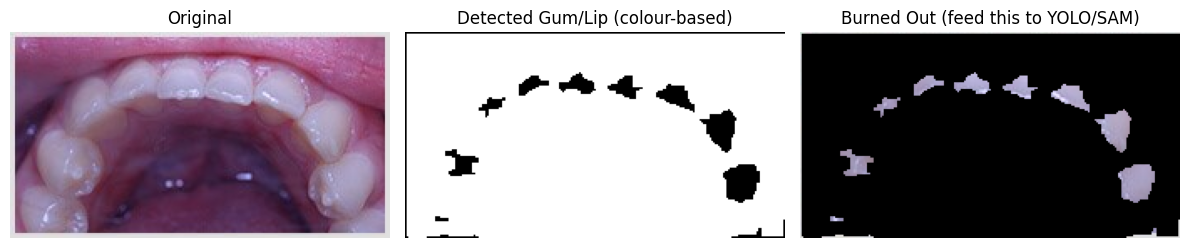

patient4-2.jpg: burned 92.7% of pixels as gum/lip -> /kaggle/working/outputs_gum_lip_suppression/patient4-2_gum_lip_suppression.png


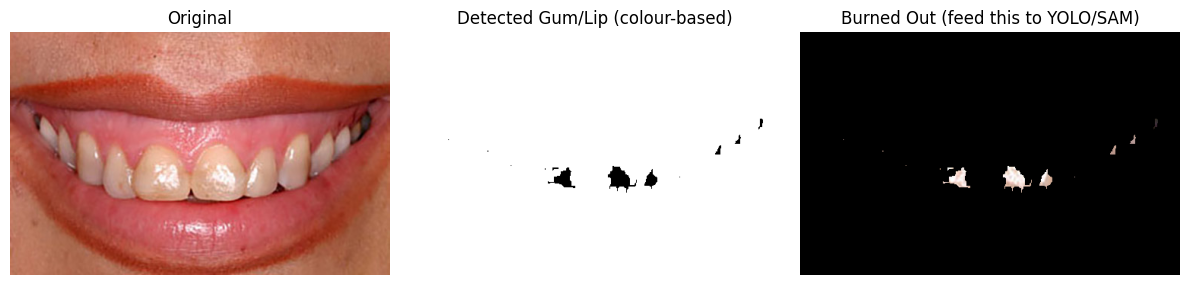

mous15.jpg: burned 99.1% of pixels as gum/lip -> /kaggle/working/outputs_gum_lip_suppression/mous15_gum_lip_suppression.png


In [8]:
import os
import random
import numpy as np
import cv2
import matplotlib.pyplot as plt

# --------------------------------------------------------------------------
# CONSTANTS
# --------------------------------------------------------------------------
# A standalone, classical (no model) pre-filter: colour-based gum/lip
# detection, run BEFORE YOLO localization and BEFORE segmentation (module_2b,
# module_3/3c), not after. See notes.md for why this needs to sit this early
# rather than as another mask-cleanup step at the end.
OUTPUT_DIR = "/kaggle/working/outputs_gum_lip_suppression"
VAL_IMAGES_DIR = "/kaggle/input/datasets/alielhenidy/tooth-dataset/Tooth dataset v4/val/images"

IMG_SIZE = 1024  # same working resolution as module_1/module_3, for a fair preview
NUM_SAMPLE_IMAGES = 15
RANDOM_SEED = 42

# Thresholds on OpenCV's Lab (true a = a_cv - 128) and HSV. Gum/lip tissue is
# reliably redder (higher a) and more saturated than enamel, which is close
# to neutral grey/cream even under warm or cool lighting - see notes.md for
# why 'a' is the primary channel and hue is deliberately not used alone.
GUM_LIP_A_THRESHOLD = 12      # true Lab 'a'; enamel sits close to 0, gum/lip well above this
GUM_LIP_SAT_THRESHOLD = 40    # HSV saturation (0-255); filters near-grey shadow noise
GUM_LIP_VALUE_FLOOR = 25      # HSV value (0-255); ignores near-black gaps between teeth

# Grows the detected gum/lip region outward by this many pixels before
# burning it out, to also catch the blended transition band right at the
# tooth-gum edge (the boundary color-leakage failure noted in
# module_3/notes.md and docs/EXPERIMENTS.md), not just pure-gum pixels.
GUM_LIP_DILATE_PX = 6

# Same cleanup recipe as module_2b/3/3c's cleanup_mask, applied to the
# gum/lip mask itself so a few stray mis-classified pixels don't create
# speckled holes in the burned-out image.
CLEANUP_CLOSE_KERNEL_SIZE = 5
CLEANUP_MIN_COMPONENT_FRACTION = 0.01

# What burned-out pixels get set to. Black matches the convention used for
# "removed" background everywhere else in this project (module_3/5's crops),
# and gives YOLO/SAM the strongest possible signal to look elsewhere.
BURN_COLOR = (0, 0, 0)


# --------------------------------------------------------------------------
# GUM/LIP COLOUR MASK
# --------------------------------------------------------------------------
def get_gum_lip_mask(image_rgb):
    """Binary mask (1 = gum/lip tissue) from colour alone - no model, no
    training data, so it can run on any framing (tight intraoral close-up or
    a fuller smile-with-chin shot) before anything else in the pipeline."""
    image_bgr = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2BGR)
    hsv = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2HSV)
    lab = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2LAB)

    saturation = hsv[:, :, 1]
    value = hsv[:, :, 2]
    true_a = lab[:, :, 1].astype(np.int16) - 128  # OpenCV shifts 'a' by 128 to fit uint8

    mask = (
        (true_a > GUM_LIP_A_THRESHOLD)
        & (saturation > GUM_LIP_SAT_THRESHOLD)
        & (value > GUM_LIP_VALUE_FLOOR)
    ).astype(np.uint8)

    mask = _cleanup_mask(mask)

    if GUM_LIP_DILATE_PX > 0:
        kernel = np.ones((GUM_LIP_DILATE_PX, GUM_LIP_DILATE_PX), np.uint8)
        mask = cv2.dilate(mask, kernel)

    return mask


def _cleanup_mask(mask, min_component_fraction=CLEANUP_MIN_COMPONENT_FRACTION,
                   close_kernel_size=CLEANUP_CLOSE_KERNEL_SIZE):
    kernel = np.ones((close_kernel_size, close_kernel_size), np.uint8)
    closed = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(closed, connectivity=8)
    if num_labels <= 1:
        return closed

    largest_area = stats[1:, cv2.CC_STAT_AREA].max()
    min_area = largest_area * min_component_fraction

    cleaned = np.zeros_like(closed)
    for label_id in range(1, num_labels):
        if stats[label_id, cv2.CC_STAT_AREA] >= min_area:
            cleaned[labels == label_id] = 1
    return cleaned


# --------------------------------------------------------------------------
# BURN-OUT
# --------------------------------------------------------------------------
def burn_out_gum_lip(image_rgb, gum_lip_mask, burn_color=BURN_COLOR):
    """Returns a copy of image_rgb with every gum/lip pixel replaced by
    burn_color. Run this BEFORE the image reaches YOLO or the segmenter -
    see notes.md for why post-hoc masking isn't equivalent."""
    burned = image_rgb.copy()
    burned[gum_lip_mask.astype(bool)] = burn_color
    return burned


# --------------------------------------------------------------------------
# VISUALIZATION
# --------------------------------------------------------------------------
def visualize_suppression(image_rgb, gum_lip_mask, burned_image, save_path):
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    axes[0].imshow(image_rgb)
    axes[0].set_title("Original")
    axes[0].axis("off")

    axes[1].imshow(gum_lip_mask, cmap="gray")
    axes[1].set_title("Detected Gum/Lip (colour-based)")
    axes[1].axis("off")

    axes[2].imshow(burned_image)
    axes[2].set_title("Burned Out (feed this to YOLO/SAM)")
    axes[2].axis("off")

    plt.tight_layout()
    plt.savefig(save_path)
    plt.show()


# --------------------------------------------------------------------------
# MAIN
# --------------------------------------------------------------------------
if __name__ == "__main__":
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    random.seed(RANDOM_SEED)

    all_images = sorted(
        f for f in os.listdir(VAL_IMAGES_DIR) if f.lower().endswith((".jpg", ".jpeg"))
    )
    sample_images = random.sample(all_images, min(NUM_SAMPLE_IMAGES, len(all_images)))

    for filename in sample_images:
        image_path = os.path.join(VAL_IMAGES_DIR, filename)
        base_name = os.path.splitext(filename)[0]

        image_bgr = cv2.imread(image_path)
        image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

        gum_lip_mask = get_gum_lip_mask(image_rgb)
        burned_image = burn_out_gum_lip(image_rgb, gum_lip_mask)

        viz_path = os.path.join(OUTPUT_DIR, f"{base_name}_gum_lip_suppression.png")
        visualize_suppression(image_rgb, gum_lip_mask, burned_image, viz_path)

        burned_percentage = 100.0 * gum_lip_mask.sum() / gum_lip_mask.size
        print(f"{filename}: burned {burned_percentage:.1f}% of pixels as gum/lip -> {viz_path}")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
<All keys matched successfully>


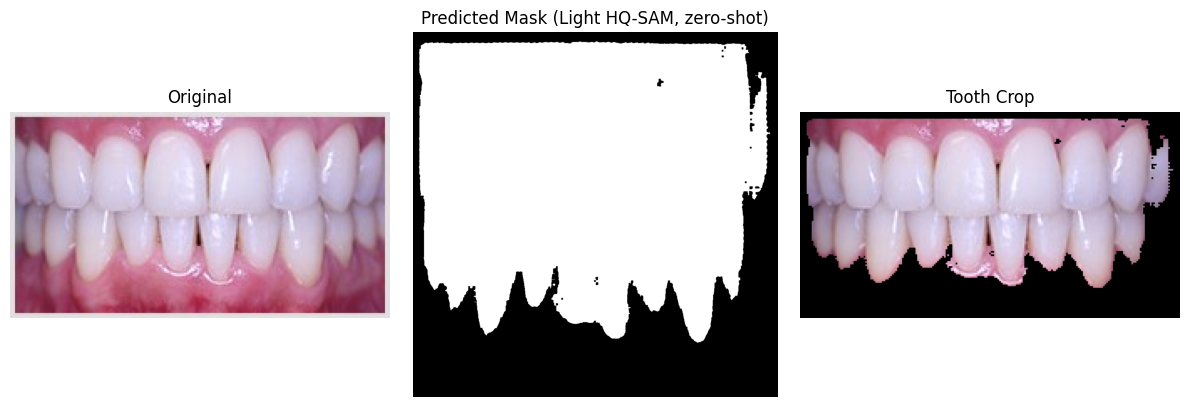

Saved tooth crop for patient9-2.jpg -> /kaggle/working/outputs_hqsam/patient9-2_tooth_crop.png


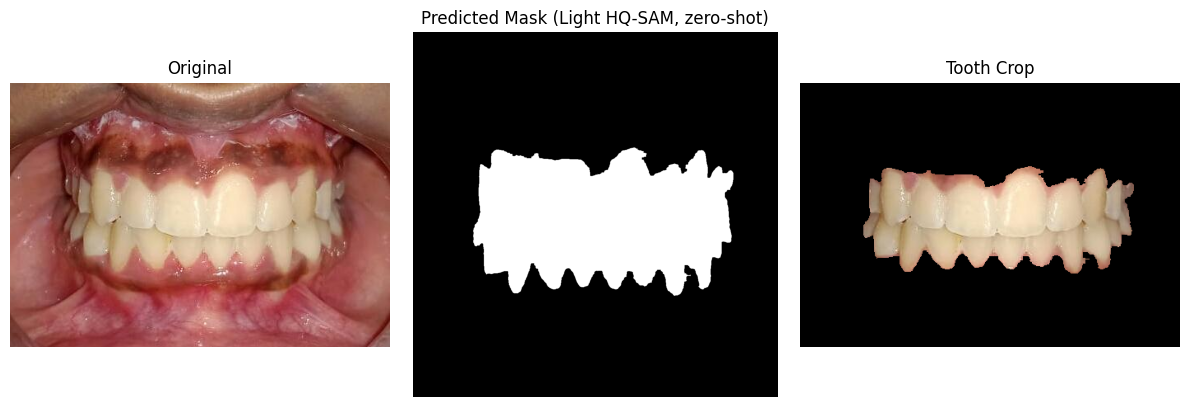

Saved tooth crop for 7836.jpg -> /kaggle/working/outputs_hqsam/7836_tooth_crop.png


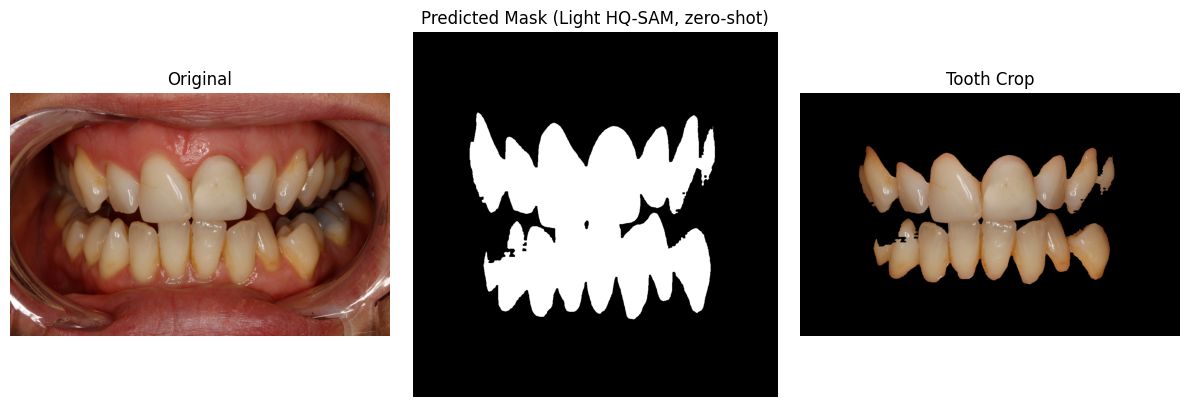

Saved tooth crop for 7018.jpg -> /kaggle/working/outputs_hqsam/7018_tooth_crop.png


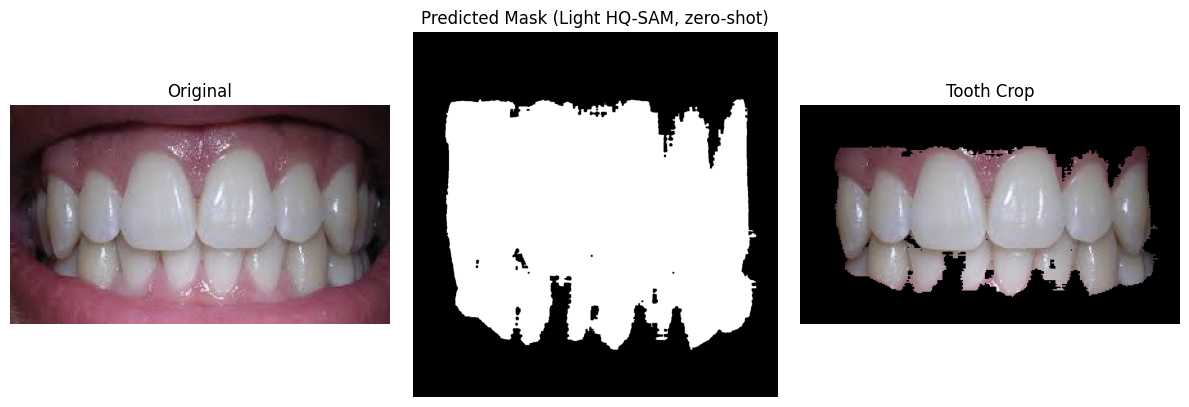

Saved tooth crop for yahya1.jpg -> /kaggle/working/outputs_hqsam/yahya1_tooth_crop.png


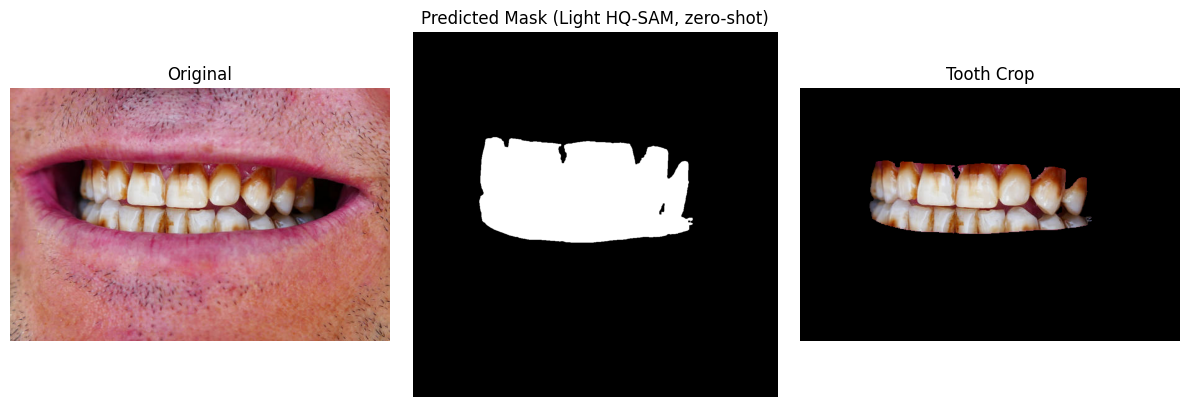

Saved tooth crop for istockphoto-1002774754-612x612.jpg -> /kaggle/working/outputs_hqsam/istockphoto-1002774754-612x612_tooth_crop.png


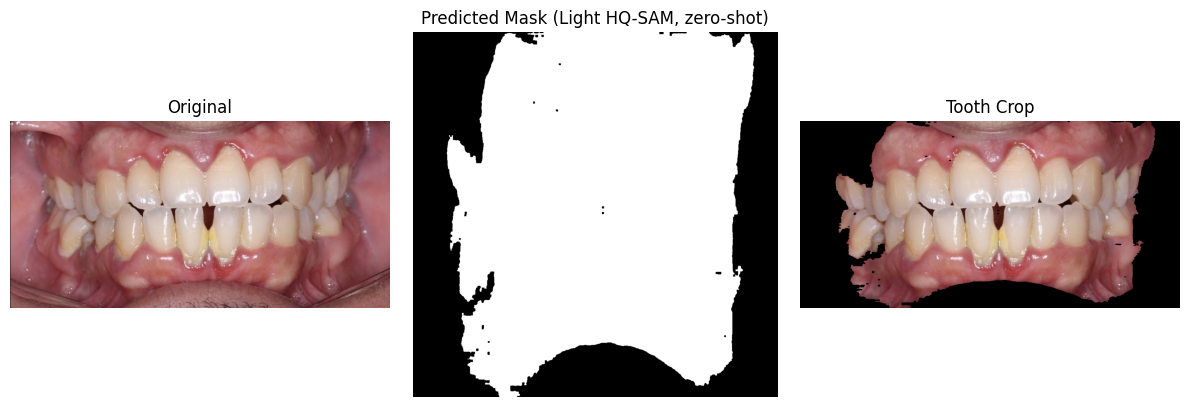

Saved tooth crop for IMG_2423.jpg -> /kaggle/working/outputs_hqsam/IMG_2423_tooth_crop.png


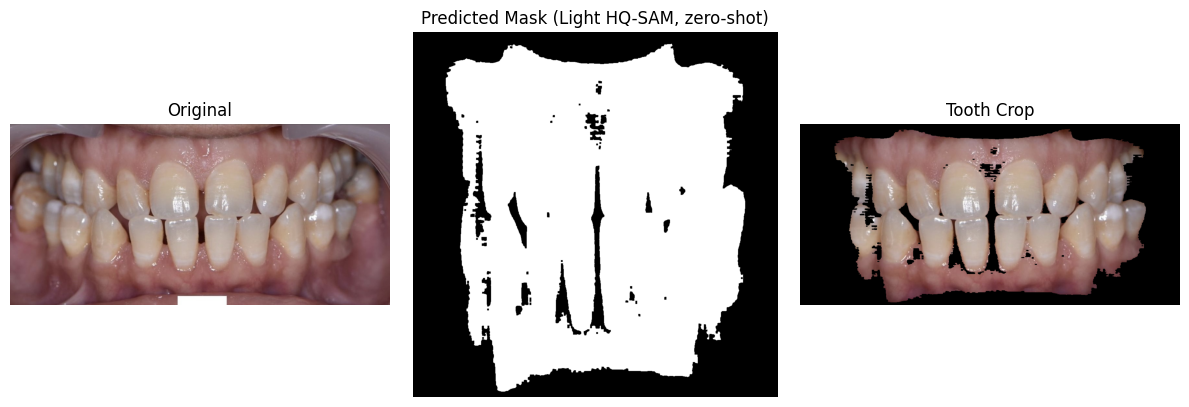

Saved tooth crop for IMG_2385.jpg -> /kaggle/working/outputs_hqsam/IMG_2385_tooth_crop.png


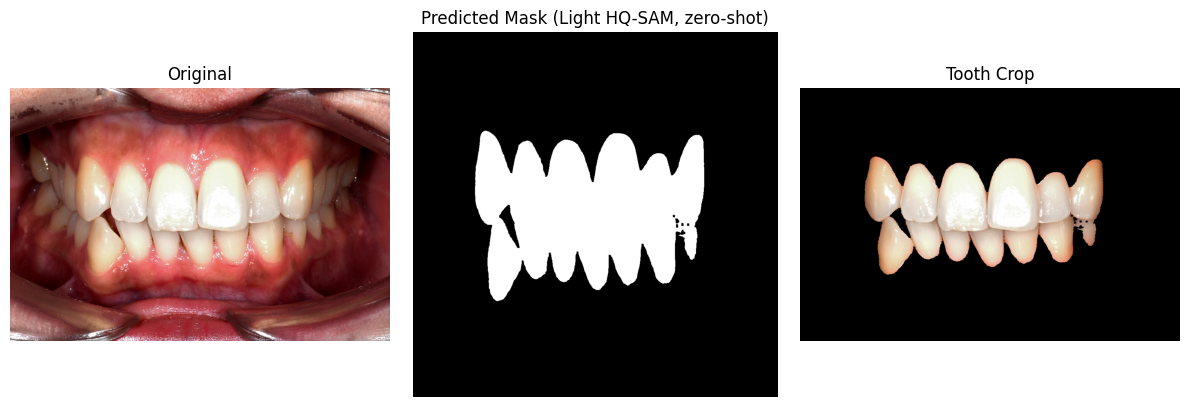

Saved tooth crop for 8764.jpg -> /kaggle/working/outputs_hqsam/8764_tooth_crop.png


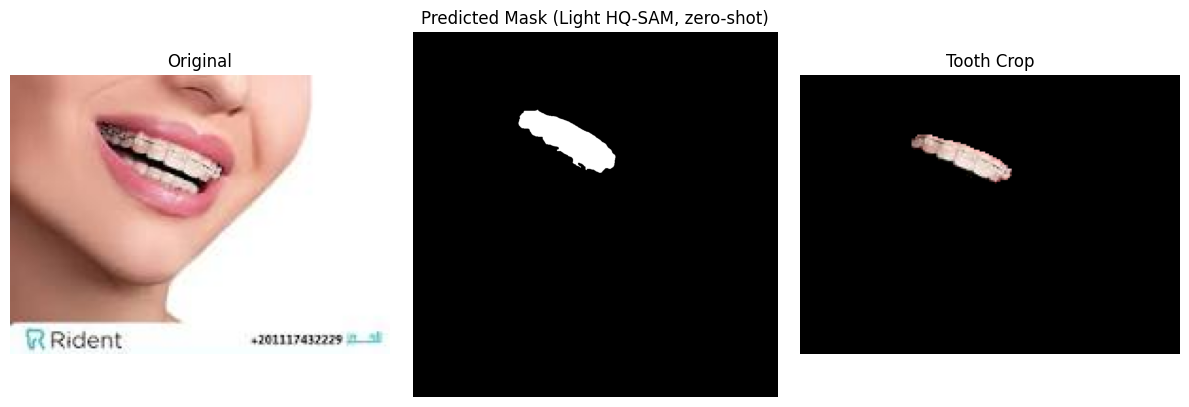

Saved tooth crop for y9.jpeg -> /kaggle/working/outputs_hqsam/y9_tooth_crop.png


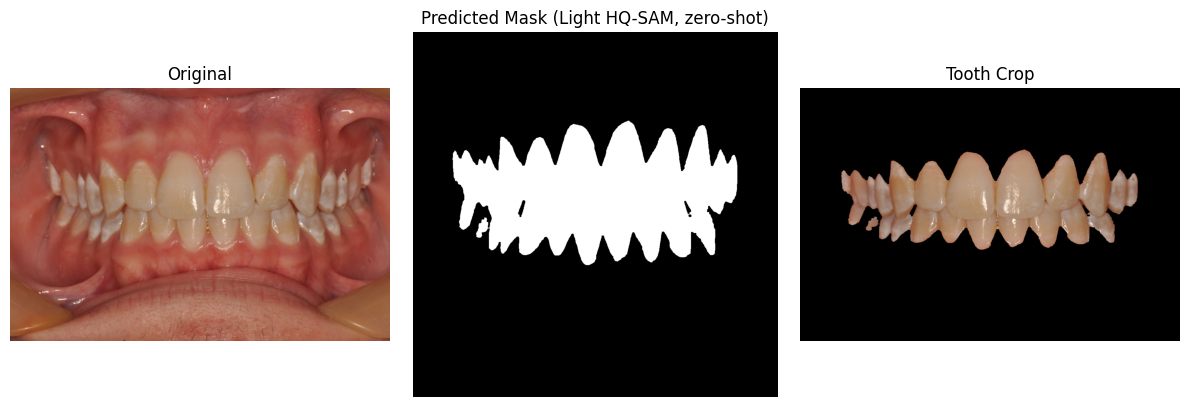

Saved tooth crop for 7758.jpg -> /kaggle/working/outputs_hqsam/7758_tooth_crop.png


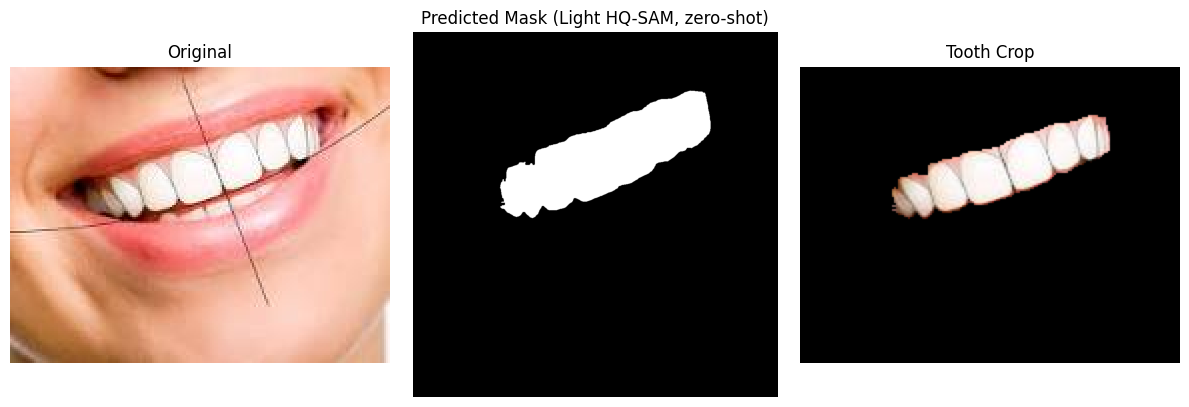

Saved tooth crop for y17.jpeg -> /kaggle/working/outputs_hqsam/y17_tooth_crop.png


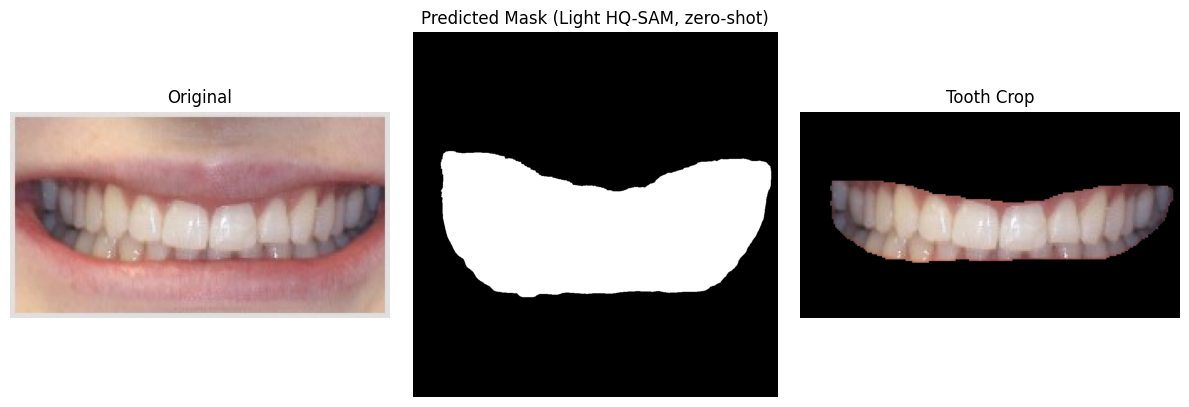

Saved tooth crop for patient17-2.jpg -> /kaggle/working/outputs_hqsam/patient17-2_tooth_crop.png


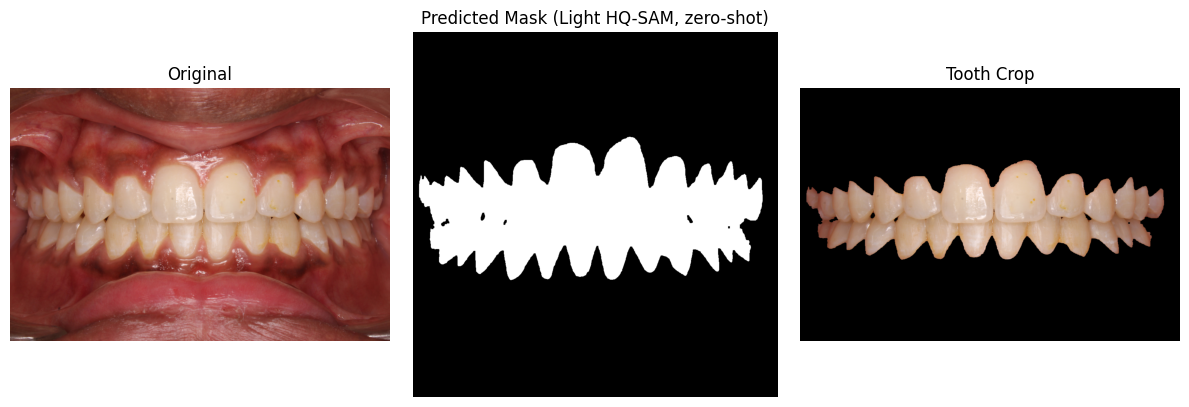

Saved tooth crop for 7625.jpg -> /kaggle/working/outputs_hqsam/7625_tooth_crop.png


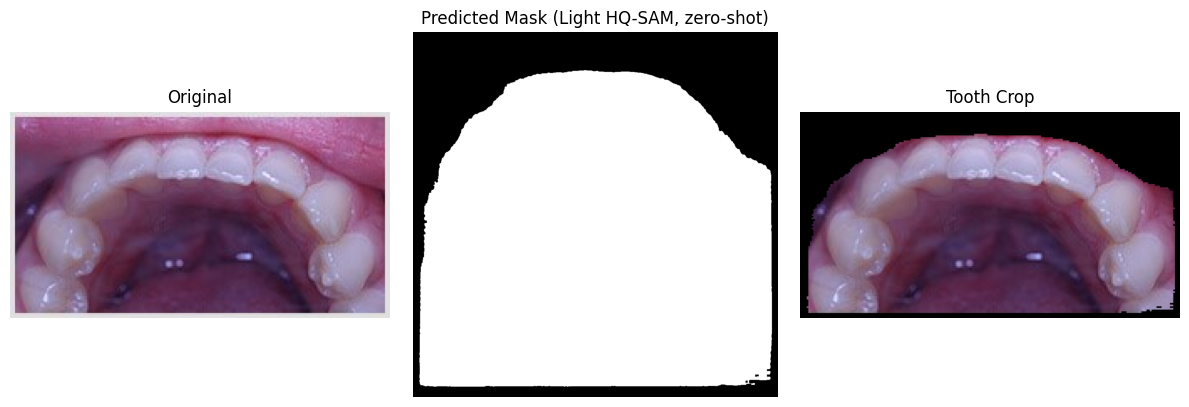

Saved tooth crop for patient4-2.jpg -> /kaggle/working/outputs_hqsam/patient4-2_tooth_crop.png


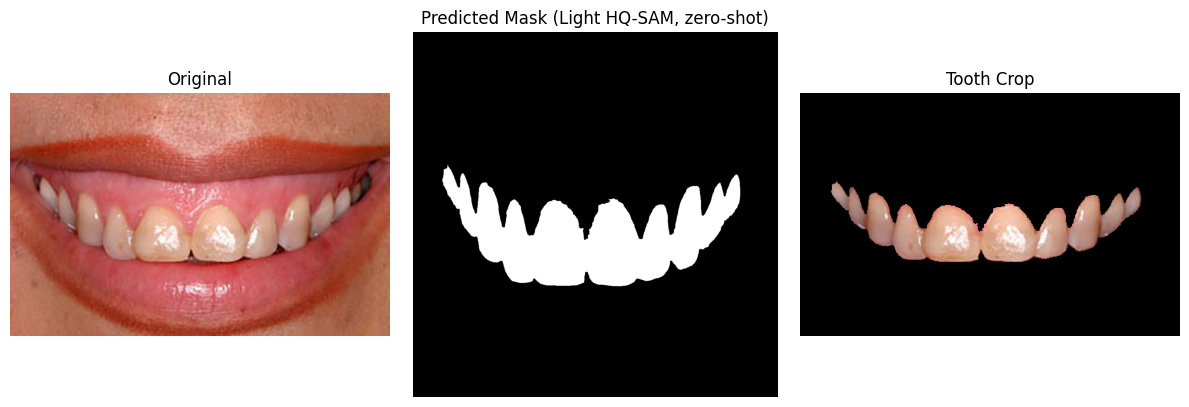

Saved tooth crop for mous15.jpg -> /kaggle/working/outputs_hqsam/mous15_tooth_crop.png


In [7]:
import os
import random
import urllib.request
import numpy as np
import torch
import cv2
import matplotlib.pyplot as plt
from skimage.transform import resize
from segment_anything import sam_model_registry, SamPredictor
from ultralytics import YOLO

# --------------------------------------------------------------------------
# CONSTANTS
# --------------------------------------------------------------------------
# Zero-shot check for Rank #1 in docs/top_10_arc_segmentation_solutions.pdf:
# does Light HQ-SAM's pretrained boundary quality alone (no fine-tuning on
# our dataset) already beat fine-tuned MedSAM? Run this in its OWN fresh
# Kaggle session. "segment-anything-hq" (pip) installs under the same
# top-level "segment_anything" module name as the original "segment-anything"
# package module_3 uses - the two cannot coexist in one environment. Install
# ONLY "segment-anything-hq" here:
#   !pip install -q segment-anything-hq ultralytics
#
# NOTE: "vit_tiny" (the literal "Light HQ-SAM" TinyViT/MobileSAM variant) is
# NOT registered in sam_model_registry from the pip package - confirmed via a
# real KeyError on Kaggle (sam-hq's tiny variant needs separate setup code
# not shipped in the pip-installable package; see
# github.com/SysCV/sam-hq/issues/130, unresolved upstream). Falling back to
# "vit_b" instead: same backbone size as our own MedSAM checkpoint, so this
# is still a fair "does HQ-SAM's boundary-focused training beat MedSAM's"
# test - just not literally the smallest edge variant, which only matters
# for the later distillation stage, not this check.
HQSAM_MODEL_TYPE = "vit_b"
HQSAM_CHECKPOINT_URL = "https://huggingface.co/lkeab/hq-sam/resolve/main/sam_hq_vit_b.pth"
HQSAM_CHECKPOINT_PATH = "/kaggle/working/sam_hq_vit_b.pth"

# Same trained detector from module_2b - localization already validated
# separately, only the segmenter changes in this experiment.
YOLO_CHECKPOINT_PATH = "/kaggle/input/datasets/hemantdarur/yolomodel-inference/yolo_checkpoints/tooth_yolo/weights/best.pt"

OUTPUT_DIR = "/kaggle/working/outputs_hqsam"
VAL_IMAGES_DIR = "/kaggle/input/datasets/alielhenidy/tooth-dataset/Tooth dataset v4/val/images"

IMG_SIZE = 1024
NUM_SAMPLE_IMAGES = 15  # same sample size/seed as module_3's runs - directly comparable
RANDOM_SEED = 42

YOLO_CONF_THRESHOLD = 0.25
YOLO_BBOX_MARGIN = 20

# HQ-SAM's own output-blending toggle (see their demo): True uses only the
# HQ-refined token, recommended for a single isolated object; False blends
# with the standard SAM token, recommended for cluttered/multi-part scenes.
# Our mask covers a whole arch of many teeth - closer to "multi-part".
HQ_TOKEN_ONLY = False

# Same mask cleanup as module_3, for a fair before/after (not the interior
# enamel ROI - that's a module_5 color-reading concern, not this module's).
ENABLE_MASK_CLEANUP = True
CLEANUP_CLOSE_KERNEL_SIZE = 5
CLEANUP_MIN_COMPONENT_FRACTION = 0.01

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# --------------------------------------------------------------------------
# MODEL LOADING
# --------------------------------------------------------------------------
def load_hqsam_model(checkpoint_path, checkpoint_url):
    if not os.path.exists(checkpoint_path):
        print(f"Downloading Light HQ-SAM checkpoint to {checkpoint_path} ...")
        urllib.request.urlretrieve(checkpoint_url, checkpoint_path)

    sam = sam_model_registry[HQSAM_MODEL_TYPE](checkpoint=checkpoint_path)
    sam.to(DEVICE)
    sam.eval()
    return SamPredictor(sam)


def load_yolo_model(checkpoint_path):
    if not os.path.exists(checkpoint_path):
        print(f"YOLO checkpoint not found at {checkpoint_path} - "
              f"falling back to no localization for this run.")
        return None
    return YOLO(checkpoint_path)


# --------------------------------------------------------------------------
# PREPROCESSING
# --------------------------------------------------------------------------
def preprocess_image(image_path):
    # Same square resize convention as module_3, so the YOLO box prompt
    # (produced in this same 1024x1024 frame) and HQ-SAM's own prediction
    # both operate in one consistent coordinate space.
    image_bgr = cv2.imread(image_path)
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

    image_resized = resize(
        image_rgb, (IMG_SIZE, IMG_SIZE), order=3, preserve_range=True, anti_aliasing=True
    )
    image_resized_uint8 = image_resized.astype(np.uint8)
    return image_rgb, image_resized_uint8


# --------------------------------------------------------------------------
# BBOX PROMPT
# --------------------------------------------------------------------------
def get_bbox_prompt_yolo(image_resized_uint8, yolo_model, margin=YOLO_BBOX_MARGIN):
    results = yolo_model.predict(image_resized_uint8, conf=YOLO_CONF_THRESHOLD, verbose=False)
    boxes = results[0].boxes.xyxy.cpu().numpy()

    if boxes.shape[0] == 0:
        return None

    x_min = boxes[:, 0].min()
    y_min = boxes[:, 1].min()
    x_max = boxes[:, 2].max()
    y_max = boxes[:, 3].max()

    h, w = image_resized_uint8.shape[:2]
    x_min = max(0, x_min - margin)
    y_min = max(0, y_min - margin)
    x_max = min(w, x_max + margin)
    y_max = min(h, y_max + margin)

    return np.array([x_min, y_min, x_max, y_max], dtype=np.float32)


# --------------------------------------------------------------------------
# MASK CLEANUP (same recipe as module_3's cleanup_mask)
# --------------------------------------------------------------------------
def cleanup_mask(mask, min_component_fraction=CLEANUP_MIN_COMPONENT_FRACTION,
                  close_kernel_size=CLEANUP_CLOSE_KERNEL_SIZE):
    kernel = np.ones((close_kernel_size, close_kernel_size), np.uint8)
    closed = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(closed, connectivity=8)
    if num_labels <= 1:
        return closed

    largest_area = stats[1:, cv2.CC_STAT_AREA].max()
    min_area = largest_area * min_component_fraction

    cleaned = np.zeros_like(closed)
    for label_id in range(1, num_labels):
        if stats[label_id, cv2.CC_STAT_AREA] >= min_area:
            cleaned[labels == label_id] = 1
    return cleaned


# --------------------------------------------------------------------------
# INFERENCE
# --------------------------------------------------------------------------
def run_inference(predictor, image_resized_uint8, bbox):
    predictor.set_image(image_resized_uint8)
    masks, _, _ = predictor.predict(
        point_coords=None,
        point_labels=None,
        box=bbox,
        multimask_output=False,
        hq_token_only=HQ_TOKEN_ONLY,
    )
    mask = masks[0].astype(np.uint8)
    if ENABLE_MASK_CLEANUP:
        mask = cleanup_mask(mask)
    return mask


# --------------------------------------------------------------------------
# TOOTH CROP EXTRACTION
# --------------------------------------------------------------------------
def extract_tooth_crop(original_image, mask, save_path):
    mask_resized = cv2.resize(
        mask, (original_image.shape[1], original_image.shape[0]), interpolation=cv2.INTER_NEAREST
    )
    mask_3ch = np.repeat(mask_resized[:, :, None], 3, axis=2)
    tooth_crop = original_image * mask_3ch

    cv2.imwrite(save_path, cv2.cvtColor(tooth_crop, cv2.COLOR_RGB2BGR))
    return tooth_crop


# --------------------------------------------------------------------------
# VISUALIZATION
# --------------------------------------------------------------------------
def visualize_result(original_image, mask, tooth_crop, save_path):
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    axes[0].imshow(original_image)
    axes[0].set_title("Original")
    axes[0].axis("off")

    axes[1].imshow(mask, cmap="gray")
    axes[1].set_title("Predicted Mask (Light HQ-SAM, zero-shot)")
    axes[1].axis("off")

    axes[2].imshow(tooth_crop)
    axes[2].set_title("Tooth Crop")
    axes[2].axis("off")

    plt.tight_layout()
    plt.savefig(save_path)
    plt.show()


# --------------------------------------------------------------------------
# MAIN
# --------------------------------------------------------------------------
if __name__ == "__main__":
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    random.seed(RANDOM_SEED)

    predictor = load_hqsam_model(HQSAM_CHECKPOINT_PATH, HQSAM_CHECKPOINT_URL)
    yolo_model = load_yolo_model(YOLO_CHECKPOINT_PATH)

    all_images = sorted(
        f for f in os.listdir(VAL_IMAGES_DIR) if f.lower().endswith((".jpg", ".jpeg"))
    )
    sample_images = random.sample(all_images, min(NUM_SAMPLE_IMAGES, len(all_images)))

    for filename in sample_images:
        image_path = os.path.join(VAL_IMAGES_DIR, filename)
        base_name = os.path.splitext(filename)[0]

        original_image, image_resized_uint8 = preprocess_image(image_path)

        bbox = None
        if yolo_model is not None:
            bbox = get_bbox_prompt_yolo(image_resized_uint8, yolo_model)
        if bbox is None:
            print(f"  No YOLO detection for {filename} - skipping (no generic-box fallback "
                  f"in this zero-shot check, to isolate the segmenter comparison).")
            continue

        mask = run_inference(predictor, image_resized_uint8, bbox)

        crop_path = os.path.join(OUTPUT_DIR, f"{base_name}_tooth_crop.png")
        tooth_crop = extract_tooth_crop(original_image, mask, crop_path)

        viz_path = os.path.join(OUTPUT_DIR, f"{base_name}_hqsam_result.png")
        visualize_result(original_image, mask, tooth_crop, viz_path)

        print(f"Saved tooth crop for {filename} -> {crop_path}")
